In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

path = '../data/raw'

In [2]:
sample_submission = pd.read_csv(f'{path}/sample_submission.csv')
train = pd.read_csv(f'{path}/train.csv')
test = pd.read_csv(f'{path}/test.csv')

In [3]:
train.head()

,id,N_Days,Drug,Age,Sex,Ascites,Hepatomegaly,Spiders,Edema,Bilirubin,Cholesterol,Albumin,Copper,Alk_Phos,SGOT,Tryglicerides,Platelets,Prothrombin,Stage,Status
0,0,999,D-penicillamine,21532,M,N,N,N,N,2.3,316.0,3.35,172.0,1601.0,179.80,63.0,394.0,9.7,3.0,D
1,1,2574,Placebo,19237,F,N,N,N,N,0.9,364.0,3.54,63.0,1440.0,134.85,88.0,361.0,11.0,3.0,C
2,2,3428,Placebo,13727,F,N,Y,Y,Y,3.3,299.0,3.55,131.0,1029.0,119.35,50.0,199.0,11.7,4.0,D
3,3,2576,Placebo,18460,F,N,N,N,N,0.6,256.0,3.50,58.0,1653.0,71.30,96.0,269.0,10.7,3.0,C
4,4,788,Placebo,16658,F,N,Y,N,N,1.1,346.0,3.65,63.0,1181.0,125.55,96.0,298.0,10.6,4.0,C


In [ ]:
CAT_FEATS = ["Drug", "Sex", "Ascites", "Hepatomegaly", "Spiders", "Edema", "Stage"]
NUM_FEATS = [x for x in train.columns if x not in CAT_FEATS and x != LABEL and x != 'id']

**profile report** 

In [4]:
# !pip install ydata-profiling

# from ydata_profiling import ProfileReport

In [5]:
profile_reports = False
if profile_reports:
  profile = ProfileReport(
                        train,
                        title="Prediction of Cirrhosis Outcomes",
                        explorative=True,
                        correlations={
                        "auto": {"calculate": False},
                        "phi_k": {"calculate": True}}
                        )
  profile

**Многомерный анализ**

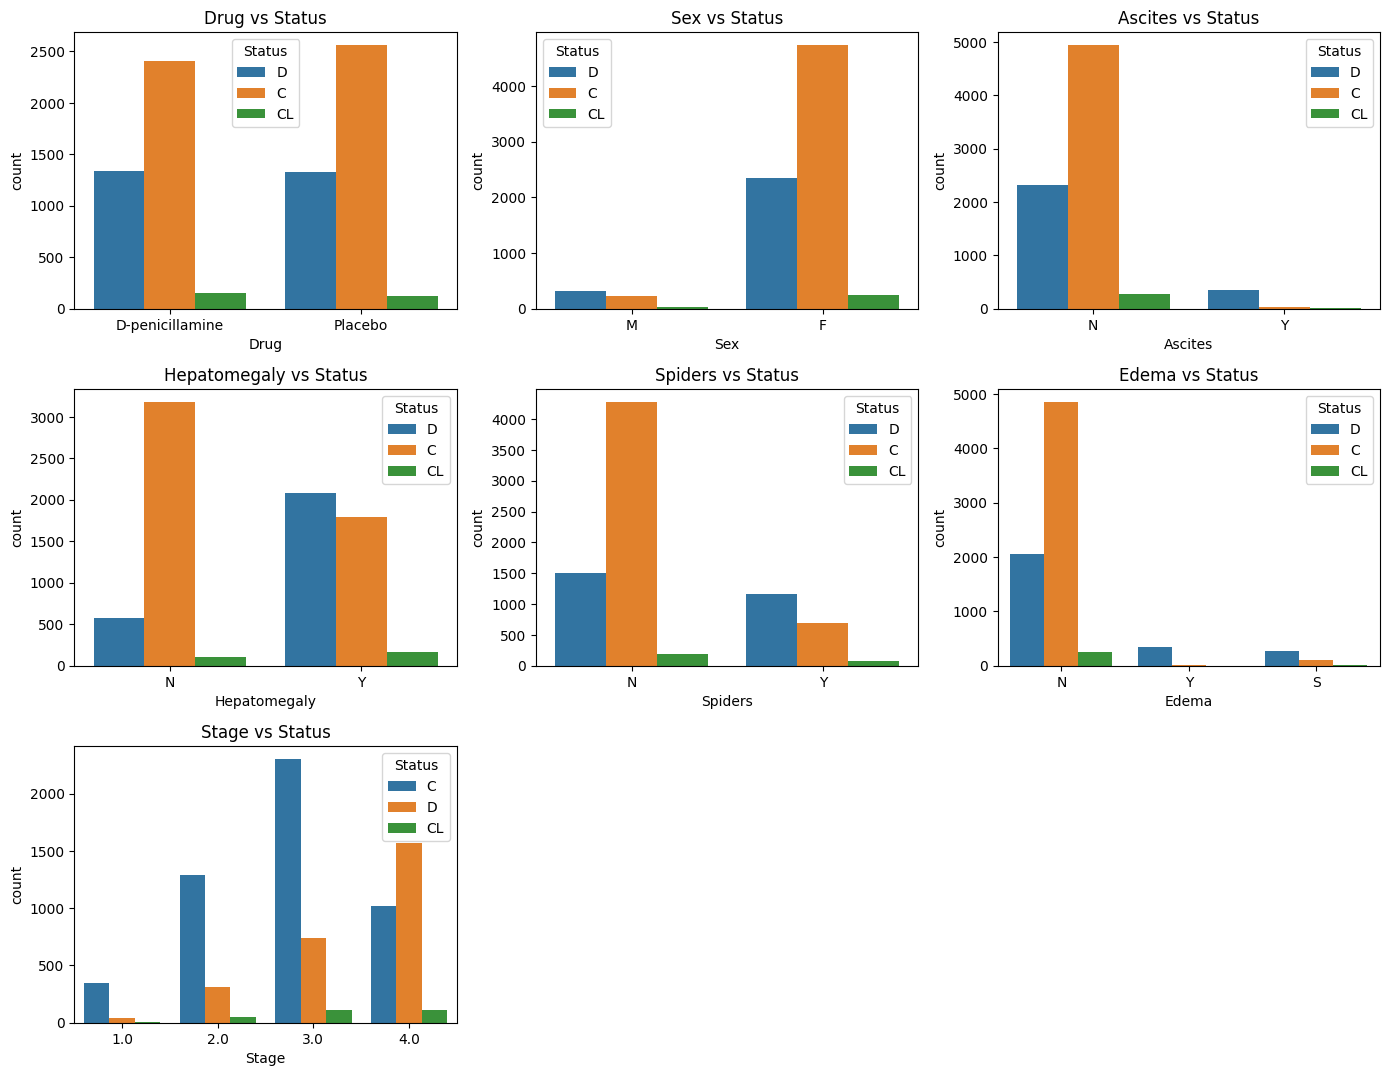

In [ ]:
# Посмотрим на категориальные признаки
 
plt.figure(figsize=(14, len(CAT_FEATS) * 2))
for i, col in enumerate(CAT_FEATS):
    plt.subplot(len(CAT_FEATS) // 2 + 1, 3, i + 1)
    sns.countplot(x=col, hue=LABEL, data=train)
    plt.title(f"{col} vs {LABEL}")
    plt.tight_layout()

Значения переменной Drug равномерно-распределены по целевоц переменной, в остальных случаях есть дисбаланс

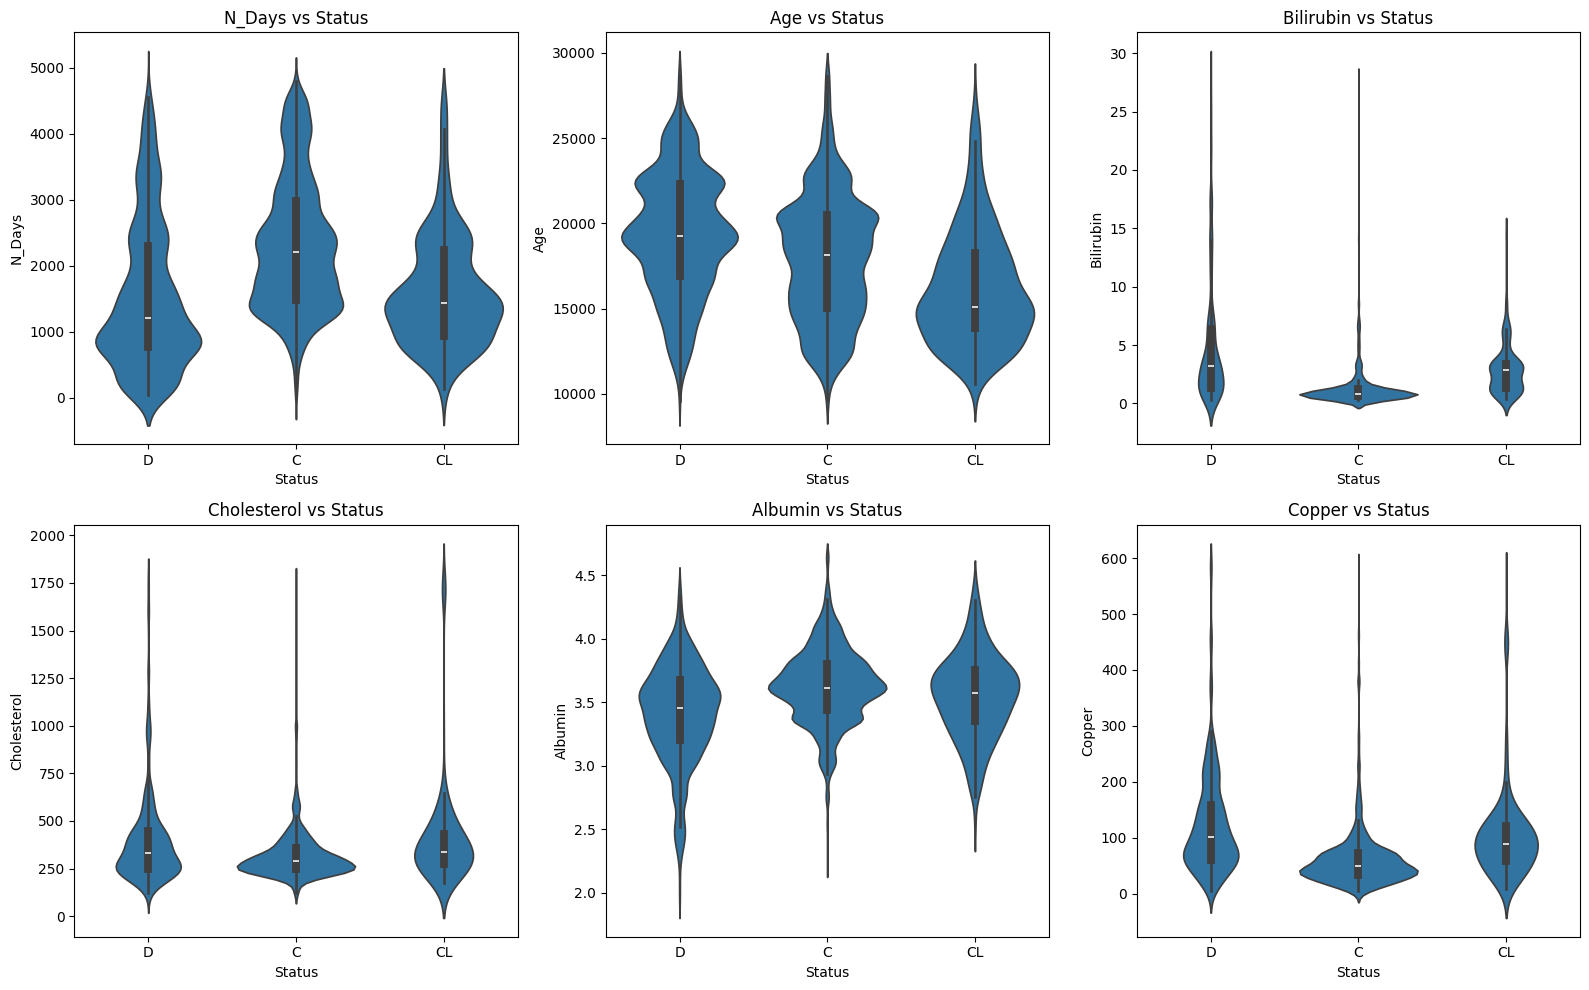

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
for i, ax in enumerate(axes.flatten()):
    sns.violinplot(x=LABEL, y=NUM_FEATS[i], data=train, ax=ax)
    ax.set_title(f"{NUM_FEATS[i]} vs {LABEL}")
plt.tight_layout()
plt.show()

На графике видны выбросы. Мы обработаем их на другом этапе.

**Корреляционный анализ**

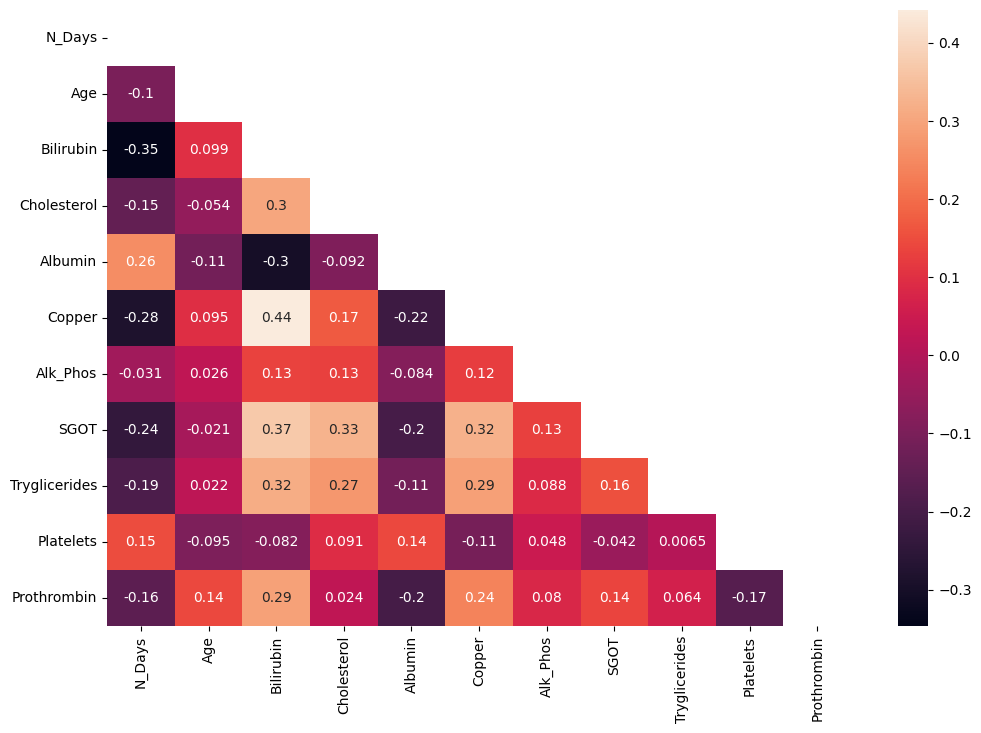

In [ ]:
plt.figure(figsize=(12, 8))
mask = np.triu(np.ones_like(train[NUM_FEATS].corr(), dtype=bool))
sns.heatmap(train[NUM_FEATS].corr(), annot=True, mask=mask)
plt.show()

Сильно коррелирующих признаков нет. Однако мы видим среднюю положительную корреляцию между медью и билирубином и среднюю отрицательную корреляцию между альбумином и билирубином.